In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
port= pd.DataFrame()

In [3]:
tickers=['ITC.NS','^NSEI']

In [4]:
for t in tickers:
    port[t] = yf.download(t, start='2022-1-1')['Close']
port

/var/folders/5b/1yvmvb2x2f753vb6qj5q9w000000gn/T/ipykernel_3371/676178987.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  port[t] = yf.download(t, start='2020-1-1')['Close']
[*********************100%***********************]  1 of 1 completed
/var/folders/5b/1yvmvb2x2f753vb6qj5q9w000000gn/T/ipykernel_3371/676178987.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  port[t] = yf.download(t, start='2020-1-1')['Close']
[*********************100%***********************]  1 of 1 completed


,ITC.NS,^NSEI
Date,,
2020-01-01,185.407303,12182.500000
2020-01-02,186.770050,12282.200195
2020-01-03,185.718796,12226.650391
2020-01-06,183.071228,11993.049805
2020-01-07,183.265915,12052.950195
...,...,...
2025-12-01,404.250000,26175.750000
2025-12-02,400.950012,26032.199219
2025-12-03,400.500000,25986.000000


In [5]:
log_returns= np.log(port/port.shift(1))
log_returns

,ITC.NS,^NSEI
Date,,
2020-01-01,NaN,NaN
2020-01-02,0.007323,0.008151
2020-01-03,-0.005645,-0.004533
2020-01-06,-0.014358,-0.019291
2020-01-07,0.001063,0.004982
...,...,...
2025-12-01,0.000000,-0.001039
2025-12-02,-0.008197,-0.005499
2025-12-03,-0.001123,-0.001776


In [22]:
pfolio_returns=[]
pfolio_volatilities=[]

for x in range(1000):
    weights=np.random.random(len(tickers))
    weights /= np.sum(weights)
    pfolio_returns.append(np.sum(weights*(log_returns.mean()*250)))
    pfolio_volatilities.append(np.sqrt(np.dot(weights.T, np.dot(log_returns.cov()*250,weights))))
pfolio_returns= np.array(pfolio_returns)
pfolio_volatilities= np.array(pfolio_volatilities)

In [23]:
portfolios=pd.DataFrame({'Returns':pfolio_returns, 'Volatility':pfolio_volatilities})
portfolios

,Returns,Volatility
0,0.131368,0.196607
1,0.131368,0.196597
2,0.130596,0.181314
3,0.131507,0.200292
4,0.130836,0.185049
...,...,...
995,0.129635,0.176747
996,0.130149,0.177058
997,0.131907,0.212220
998,0.129352,0.178690


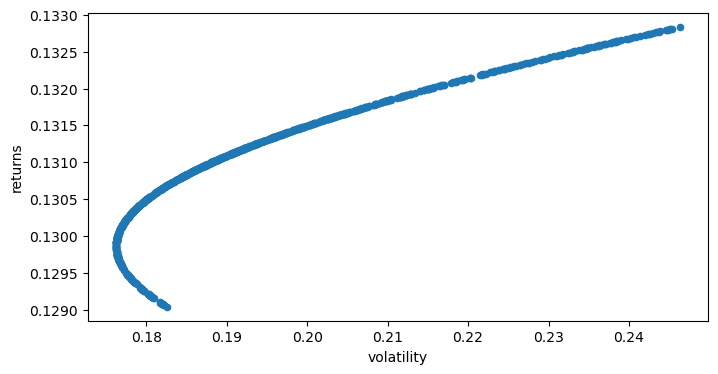

In [8]:
portfolios.plot(x='Volatility', y= 'Returns', kind='scatter', figsize=(8,4))
plt.xlabel('volatility')
plt.ylabel('returns')
plt.show()

Calculating expected return of ITC shares using CAPM method

In [10]:
cov=log_returns.cov()*250
cov

,ITC.NS,^NSEI
ITC.NS,0.061048,0.022770
^NSEI,0.022770,0.033368


In [11]:
cov_with_market=cov.iloc[0,1]
cov_with_market

np.float64(0.0227696413916188)

In [12]:
market_var= log_returns['^NSEI'].var()*250

In [13]:
INFY_beta= cov_with_market/market_var
INFY_beta

np.float64(0.6823718766071902)

In [21]:
INFY_exp_return= 0.065 + INFY_beta*0.07
print(str(round(INFY_exp_return*100, 2)) + str('%'))

11.28%
